# 細胞種で発火率を分けた閾値

`loom_threshold.ipynb` は、LC4 も LPLC2 も同じ拡大速度で 80 Hz まで上げていた。計測では役割が分かれている。LC4 は拡大速度、LPLC2 は視角の大きさで、大きさの山はおよそ 40° にある（Ache ほか、2019）。ここではその分け方だけを入れ、50 Hz、80 Hz、拡大速度 50 rad/s、膜の閾値 1 は変えない。

LC4 の発火率は前と同じである。

$$
r^{\mathrm{LC4}}_i = 80\,\mathrm{Hz}\,\mathrm{clip}(\dot\theta / 50,\, 0,\, 1)\, f_i
$$

LPLC2 は、球の視角 \(\theta = 2\arctan(R/d)\) のガウス関数にする。山は 40°、幅 \(\sigma = 20°\) である。40° は計測の山に合わせた。幅は計測のフィットではなく、山の前後で下がるように置いた値である。

$$
g(\theta) = \exp\left(-\frac{(\theta - 40°)^2}{2\sigma^2}\right), \qquad
r^{\mathrm{LPLC2}}_i = 80\,\mathrm{Hz}\, g(\theta)\, f_i
$$

電流はどちらの細胞種も、同じ \(W_{\mathrm{side}}\) で割る。

$$
I = \sum_i \frac{w_i}{W_{\mathrm{side}}} \frac{r_i}{50\,\mathrm{Hz}}
$$

片眼の全細胞が 80 Hz のとき、合計は前と同じ 1.6 である。LPLC2 だけでは最大でも左 0.66、右 0.74 なので、1 本の細胞種では閾値を超えない。比較の「速度だけ」は、LPLC2 にも LC4 と同じ \(\mathrm{clip}\) を掛けた前回の合計である。


In [1]:
from pathlib import Path
import sys

import japanize_matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.feather as feather

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "data" / "malecns" / "gf-loom" / "neurons.feather").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from flycar.fov import Scene

DATA = ROOT / "data" / "malecns" / "gf-loom"
LC4_CACHE = ROOT / "data" / "malecns" / "lc4-camera" / "lc4_lobula_posts.npz"
LPLC2_CACHE = ROOT / "data" / "malecns" / "lplc2-camera" / "lplc2_lobula_posts.npz"
R_MAX, R_REF, THETA_DOT_SAT = 80.0, 50.0, 50.0
SCALE = R_MAX / R_REF
SIZE_PEAK_DEG, SIZE_SIGMA_DEG = 40.0, 20.0
TAU_MS, V_THRESHOLD, REFRAC_MS = 5.0, 1.0, 5.0
DT, GEOM_DT = 0.001, 0.005
if abs(GEOM_DT / DT - round(GEOM_DT / DT)) > 1e-9:
    raise RuntimeError("幾何の刻みが膜の刻みの整数倍でない。")
REPEATS = int(round(GEOM_DT / DT))
CHUNK = 8


## 細胞とカメラ

画面上の位置と、DNp01 へのシナプス数は `loom_threshold.ipynb` と同じである。LPLC2 は小葉板の列、LC4 は小葉の列を使う。


In [2]:
def image_uv(ab, side, left_ab, right_ab):
    # u is 0 at the left edge and 1 at the right edge. v is 0 at the top.
    u = np.empty(len(ab), dtype=np.float64)
    v = np.empty(len(ab), dtype=np.float64)
    for code_side, grid in ((0, left_ab), (1, right_ab)):
        valid = grid[:, 0] >= 0
        a0, a1 = grid[valid, 0].min(), grid[valid, 0].max()
        b0, b1 = grid[valid, 1].min(), grid[valid, 1].max()
        mask = side == code_side
        lateral = (ab[mask, 0] - a0) / (a1 - a0)
        if code_side == 0:
            u[mask] = 0.5 * (1.0 - lateral)
        else:
            u[mask] = 0.5 + 0.5 * lateral
        v[mask] = (ab[mask, 1] - b0) / (b1 - b0)
    return u, v


def load_population(pack, keys, weight_of, side_of):
    body = pack[keys[0]]
    ab = pack[keys[1]]
    side = pack[keys[2]]
    u, v = image_uv(ab, side, pack[keys[3]], pack[keys[4]])
    order = np.argsort(body, kind="mergesort")
    body, u, v, side = body[order], u[order], v[order], side[order]
    if np.any((u < -1e-9) | (u > 1 + 1e-9) | (v < -1e-9) | (v > 1 + 1e-9)):
        raise RuntimeError("画面の外に出る後シナプスがある。")
    cuts = np.flatnonzero(np.diff(body)) + 1
    starts = np.r_[0, cuts]
    cell_n = np.diff(np.r_[starts, len(body)]).astype(np.float64)
    cell_id = body[starts]
    cell_side = side[starts]
    if np.any(np.maximum.reduceat(side, starts) != np.minimum.reduceat(side, starts)):
        raise RuntimeError("片眼に収まらない細胞がある。")
    names = side_of.loc[cell_id].to_numpy()
    expect = np.where(names == "L", np.int8(0), np.int8(1))
    if not np.array_equal(expect, cell_side):
        raise RuntimeError("画面の左右と注釈の左右が違う。")
    missing = [int(i) for i in cell_id if int(i) not in weight_of]
    if missing:
        raise RuntimeError(f"DNp01 への辺が無い細胞がある。先頭 {missing[:5]}")
    cell_w = np.array([weight_of[int(i)] for i in cell_id], dtype=np.float64)
    return {
        "u": np.ascontiguousarray(u),
        "v": np.ascontiguousarray(v),
        "starts": starts,
        "n": cell_n,
        "id": cell_id,
        "side": cell_side,
        "w": cell_w,
        "sum": np.array([cell_w[cell_side == code].sum() for code in (0, 1)]),
    }


neurons = feather.read_table(DATA / "neurons.feather").to_pandas()
edges = feather.read_table(DATA / "edges.feather").to_pandas()
gf = neurons.loc[neurons.type == "DNp01", ["bodyId", "side"]].rename(
    columns={"bodyId": "body_post", "side": "side_post"}
)
side_of = neurons.set_index("bodyId")["side"]


def weight_onto(type_name):
    pre = neurons.loc[neurons.type == type_name, ["bodyId", "side"]].rename(
        columns={"bodyId": "body_pre", "side": "side_pre"}
    )
    part = edges.merge(pre, on="body_pre").merge(gf, on="body_post")
    if not (part.side_pre == part.side_post).all():
        raise RuntimeError(f"対側への {type_name} → DNp01 がある。")
    if not part.nt_sign.eq(1).all():
        raise RuntimeError(f"{type_name} → DNp01 にアセチルコリン以外がある。")
    return dict(zip(part.body_pre.astype(np.int64), part.weight.astype(np.float64)))


lc4 = load_population(
    np.load(LC4_CACHE),
    ("body", "ab", "side", "left_ab", "right_ab"),
    weight_onto("LC4"),
    side_of,
)
lplc = load_population(
    np.load(LPLC2_CACHE),
    ("lop_body", "lop_ab", "lop_side", "lop_left_ab", "lop_right_ab"),
    weight_onto("LPLC2"),
    side_of,
)
side_ref = lc4["sum"] + lplc["sum"]
for index, name in ((0, "左"), (1, "右")):
    lc4_i = lc4["sum"][index] / side_ref[index] * SCALE
    lplc_i = lplc["sum"][index] / side_ref[index] * SCALE
    print(
        f"{name}  LC4 {int((lc4['side'] == index).sum())} 本 {lc4['sum'][index]:.0f}"
        f"    LPLC2 {int((lplc['side'] == index).sum())} 本 {lplc['sum'][index]:.0f}"
        f"    基準 {side_ref[index]:.0f}"
        f"    全部 80 Hz の電流  LC4 {lc4_i:.3f}  LPLC2 {lplc_i:.3f}  両方 {SCALE:.3f}"
    )
if abs(lc4["sum"][0] / side_ref[0] * SCALE - 0.942) > 0.002:
    raise RuntimeError("左の LC4 だけの上限が 0.942 でない。")
if abs(lc4["sum"][1] / side_ref[1] * SCALE - 0.860) > 0.002:
    raise RuntimeError("右の LC4 だけの上限が 0.860 でない。")

scene = Scene()
hfov, vfov = scene.fovs()
pitch = float(np.deg2rad(scene.pitch_deg))
cam = np.array([0.0, 0.0, scene.cam_h])
forward = np.array([1.0, 0.0, 0.0])
left = np.array([0.0, 1.0, 0.0])
up = np.array([0.0, 0.0, 1.0])
optical = forward * np.cos(pitch) - up * np.sin(pitch)
cam_up = forward * np.sin(pitch) + up * np.cos(pitch)
cam_right = -left
tan_h = float(np.tan(hfov / 2.0))
tan_v = float(np.tan(vfov / 2.0))
print(f"水平 {np.rad2deg(hfov):.1f}°  垂直 {np.rad2deg(vfov):.1f}°")


左  LC4 71 本 3782    LPLC2 94 本 2642    基準 6424    全部 80 Hz の電流  LC4 0.942  LPLC2 0.658  両方 1.600
右  LC4 55 本 2580    LPLC2 91 本 2220    基準 4800    全部 80 Hz の電流  LC4 0.860  LPLC2 0.740  両方 1.600
水平 51.6°  垂直 30.4°


## 電流

幾何は 5 ms、膜は 1 ms である。時定数 5 ms、閾値 1、不応期 5 ms。視角は球の中心までの距離から出す。画面の外にはみ出していても、球そのものの視角を LPLC2 に使う。円に入った割合 \(f_i\) が、どの細胞にその発火率を配るかを決める。


In [3]:
def covered_weight(pop, cu, cv, ru, rv, active):
    # 円に入った割合を重みづけした合計。戻り値は時刻ごとの左と右。
    out = np.zeros((len(cu), 2), dtype=np.float64)
    idx = np.flatnonzero(active)
    syn_u, syn_v = pop["u"], pop["v"]
    starts, cell_n = pop["starts"], pop["n"]
    masks = [pop["side"] == 0, pop["side"] == 1]
    weights = [pop["w"][mask] for mask in masks]
    for start in range(0, len(idx), CHUNK):
        sel = idx[start:start + CHUNK]
        du = (syn_u[None, :] - cu[sel, None]) / ru[sel, None]
        dv = (syn_v[None, :] - cv[sel, None]) / rv[sel, None]
        inside = ((du * du + dv * dv) <= 1.0).astype(np.float64)
        frac = np.add.reduceat(inside, starts, axis=1) / cell_n
        for code_side in (0, 1):
            out[sel, code_side] = frac[:, masks[code_side]] @ weights[code_side]
    return out


def project_many(positions, radius):
    rel = positions - cam
    depth = rel @ optical
    valid = depth > 1e-4
    depth_safe = np.where(valid, depth, np.inf)
    nx = (rel @ cam_right) / depth_safe / tan_h
    ny = (rel @ cam_up) / depth_safe / tan_v
    cu = (nx + 1.0) / 2.0
    cv = (1.0 - ny) / 2.0
    ru = (radius / depth_safe) / tan_h / 2.0
    rv = (radius / depth_safe) / tan_v / 2.0
    active = (
        valid
        & (ru > 1e-8)
        & (rv > 1e-8)
        & (cu + ru >= 0.0)
        & (cu - ru <= 1.0)
        & (cv + rv >= 0.0)
        & (cv - rv <= 1.0)
    )
    return cu, cv, ru, rv, active


def expansion_many(positions, velocity, radius):
    rel = positions - cam
    dist = np.linalg.norm(rel, axis=1)
    theta = 2.0 * np.arctan(radius / dist)
    closing = -(rel @ velocity) / dist
    theta_dot = np.maximum(2.0 * radius * closing / (dist * dist + radius * radius), 0.0)
    return theta, theta_dot


def size_gain(theta):
    deg = np.rad2deg(theta)
    return np.exp(-0.5 * ((deg - SIZE_PEAK_DEG) / SIZE_SIGMA_DEG) ** 2)


def lif_count(drive):
    v = 0.0
    silent_until = 0
    refrac_steps = int(round(REFRAC_MS / (DT * 1000)))
    step = (DT * 1000) / TAU_MS
    count = 0
    voltage = np.empty(len(drive))
    for i, value in enumerate(drive):
        if i < silent_until:
            v = 0.0
            voltage[i] = 0.0
            continue
        v += step * (-v + float(value))
        if v >= V_THRESHOLD:
            voltage[i] = V_THRESHOLD
            count += 1
            v = 0.0
            silent_until = i + refrac_steps
        else:
            voltage[i] = v
    return count, voltage


def approach_path(radius, speed, offset, window=0.40):
    samples = int(round(window / GEOM_DT)) + 1
    distance = np.linspace(radius + speed * window, radius, samples)
    positions = cam + optical * distance[:, None] + left * offset
    return positions, -optical * speed


def passage_path(radius, speed, distance):
    # 画像の左の外から右の外へ、光軸から distance の面を横切る。
    half = distance * tan_h + radius + 0.05
    samples = int(round(2.0 * half / speed / GEOM_DT)) + 1
    lateral = np.linspace(half, -half, samples)
    positions = cam + optical * distance + left * lateral[:, None]
    return positions, -left * speed


def simulate(positions, velocity, radius, keep=False):
    theta, theta_dot = expansion_many(positions, velocity, radius)
    cu, cv, ru, rv, active = project_many(positions, radius)
    w_lc4 = covered_weight(lc4, cu, cv, ru, rv, active)
    w_lplc = covered_weight(lplc, cu, cv, ru, rv, active)
    clip = np.clip(theta_dot / THETA_DOT_SAT, 0.0, 1.0)
    gain = size_gain(theta)
    currents = {
        "LC4": clip[:, None] * SCALE * w_lc4 / side_ref,
        "LPLC2": gain[:, None] * SCALE * w_lplc / side_ref,
        "速度だけ": clip[:, None] * SCALE * (w_lc4 + w_lplc) / side_ref,
    }
    currents["合計"] = currents["LC4"] + currents["LPLC2"]
    peak = int(np.argmax(currents["合計"][:, 0]))
    summary = {
        "視角": float(np.rad2deg(theta.max())),
        "拡大速度": float(theta_dot.max()),
        "合計時の視角左": float(np.rad2deg(theta[peak])),
        "合計時の拡大左": float(theta_dot[peak]),
        "合計時の大きさ左": float(gain[peak]),
    }
    detail = None
    if keep:
        detail = {
            "geom_time": np.arange(len(theta)) * GEOM_DT,
            "time": np.arange(len(theta) * REPEATS) * DT,
            "theta_deg": np.rad2deg(theta),
            "gain": gain,
            "clip": clip,
            "current": currents,
            "voltage": {},
        }
    for name, current in currents.items():
        expanded = np.repeat(current, REPEATS, axis=0)
        left_n, left_v = lif_count(expanded[:, 0])
        right_n, right_v = lif_count(expanded[:, 1])
        summary[f"{name}電流左"] = float(current[:, 0].max())
        summary[f"{name}電流右"] = float(current[:, 1].max())
        summary[f"{name}スパイク左"] = left_n
        summary[f"{name}スパイク右"] = right_n
        if keep:
            detail["voltage"][name] = np.column_stack([left_v, right_v])
    return summary, detail


degrees = np.array([10, 20, 30, 40, 50, 60, 75, 90], dtype=float)
gains = size_gain(np.deg2rad(degrees))
print("視角での LPLC2 の利得  山 40°  幅 20°")
print("  ".join(f"{deg:.0f}°={gain:.2f}" for deg, gain in zip(degrees, gains)))

check, _ = simulate(*approach_path(0.05, 2.0, 0.0), 0.05)
print(
    f"正面 5 cm、2 m/s  視角 {check['視角']:.1f}°  拡大速度 {check['拡大速度']:.2f}  "
    f"速度だけの電流 {check['速度だけ電流左']:.3f}  スパイク {check['速度だけスパイク左']}/{check['速度だけスパイク右']}  "
    f"分けた合計 {check['合計電流左']:.3f}  スパイク {check['合計スパイク左']}/{check['合計スパイク右']}  "
    f"山の時刻の視角 {check['合計時の視角左']:.0f}°"
)
if abs(check["視角"] - 90.0) > 0.1 or abs(check["拡大速度"] - 40.0) > 0.1:
    raise RuntimeError("正面 5 cm、2 m/s の視角か拡大速度が想定と違う。")
if abs(check["速度だけ電流左"] - 1.28) > 0.02 or check["速度だけスパイク左"] < 1:
    raise RuntimeError("速度だけの比較が前回の正面接近と違う。")


視角での LPLC2 の利得  山 40°  幅 20°
10°=0.32  20°=0.61  30°=0.88  40°=1.00  50°=0.88  60°=0.61  75°=0.22  90°=0.04
正面 5 cm、2 m/s  視角 90.0°  拡大速度 40.00  速度だけの電流 1.280  スパイク 1/1  分けた合計 0.826  スパイク 0/0  山の時刻の視角 53°


## 接近

球は光軸に沿って近づき、視角 90° で止める。正面はオフセット 0、左からと右からはカメラ左方向へ 0.15 m ずらす。半径は 3、5、8、12、20、40 cm。速度は 0.5、1、2、4、8 m/s。最後の 0.40 s を使う。


In [4]:
RADII = [0.03, 0.05, 0.08, 0.12, 0.20, 0.40]
SPEEDS = [0.5, 1.0, 2.0, 4.0, 8.0]
approach_rows = []
for offset, where in ((0.0, "正面"), (0.15, "左"), (-0.15, "右")):
    for radius in RADII:
        for speed in SPEEDS:
            positions, velocity = approach_path(radius, speed, offset)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"経路": where, "半径": radius, "速度": speed})
            approach_rows.append(summary)

approach = pd.DataFrame(approach_rows)
front_cols = [
    "半径", "速度", "視角", "拡大速度",
    "LC4電流左", "LPLC2電流左", "合計電流左", "速度だけ電流左",
    "合計時の視角左", "合計時の拡大左", "合計時の大きさ左",
    "合計スパイク左", "合計スパイク右", "速度だけスパイク左",
]
front = approach.loc[approach["経路"].eq("正面"), front_cols]
print("正面")
print(front.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print()
offset_view = (
    approach.loc[approach["経路"].ne("正面")]
    .groupby(["経路", "半径"], as_index=False)
    .agg(
        拡大速度=("拡大速度", "max"),
        LC4電流左=("LC4電流左", "max"),
        LPLC2電流左=("LPLC2電流左", "max"),
        合計電流左=("合計電流左", "max"),
        合計電流右=("合計電流右", "max"),
        速度だけ電流左=("速度だけ電流左", "max"),
        合計スパイク左=("合計スパイク左", "sum"),
        合計スパイク右=("合計スパイク右", "sum"),
        速度だけスパイク左=("速度だけスパイク左", "sum"),
        速度だけスパイク右=("速度だけスパイク右", "sum"),
    )
)
print("左右に 0.15 m ずらした接近。スパイクは速度 5 通りの合計")
print(offset_view.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(
    "分けた式のスパイク合計",
    int(approach["合計スパイク左"].sum() + approach["合計スパイク右"].sum()),
    "   速度だけ",
    int(approach["速度だけスパイク左"].sum() + approach["速度だけスパイク右"].sum()),
    "   LC4 だけ",
    int(approach["LC4スパイク左"].sum() + approach["LC4スパイク右"].sum()),
    "   LPLC2 だけ",
    int(approach["LPLC2スパイク左"].sum() + approach["LPLC2スパイク右"].sum()),
)


正面
   半径    速度     視角    拡大速度  LC4電流左  LPLC2電流左  合計電流左  速度だけ電流左  合計時の視角左  合計時の拡大左  合計時の大きさ左  合計スパイク左  合計スパイク右  速度だけスパイク左
0.030 0.500 90.000  16.667   0.314     0.558  0.665    0.533   49.550    5.854     0.892        0        0          0
0.030 1.000 90.000  33.333   0.628     0.558  0.775    1.067   53.130   13.333     0.806        0        0          0
0.030 2.000 90.000  66.667   0.942     0.553  1.063    1.600   73.740   48.000     0.241        1        1          2
0.030 4.000 90.000 133.333   0.942     0.553  1.303    1.600   61.928   70.588     0.548        1        1          2
0.030 8.000 90.000 266.667   0.942     0.553  1.420    1.600   46.397   82.759     0.950        1        1          1
0.050 0.500 90.000  10.000   0.188     0.558  0.620    0.320   49.888    3.557     0.885        0        0          0
0.050 1.000 90.000  20.000   0.377     0.557  0.685    0.640   50.927    7.394     0.861        0        0          0
0.050 2.000 90.000  40.000   0.754     0.557  0.826  

## 通過

球は光軸から一定の距離の面を、画像の左の外から右の外へ横切る。距離は 0.30 m、0.50 m、1.0 m。速度は 0.5、2、8 m/s。LPLC2 の山は 40° 付近なので、通過でも視角がそこへ近づけば電流は上がる。LPLC2 だけの上限は 1 未満なので、LC4 が足らないかぎり発火しない。


In [5]:
DISTANCES = [0.30, 0.50, 1.00]
PASS_SPEEDS = [0.5, 2.0, 8.0]
passage_rows = []
for distance in DISTANCES:
    for radius in RADII:
        for speed in PASS_SPEEDS:
            positions, velocity = passage_path(radius, speed, distance)
            summary, _ = simulate(positions, velocity, radius)
            summary.update({"距離": distance, "半径": radius, "速度": speed})
            passage_rows.append(summary)

passage = pd.DataFrame(passage_rows)
peak = (
    passage.groupby(["距離", "半径"], as_index=False)
    .agg(
        視角=("視角", "max"),
        拡大速度=("拡大速度", "max"),
        LC4電流=("LC4電流左", "max"),
        LPLC2電流=("LPLC2電流左", "max"),
        合計電流=("合計電流左", "max"),
        速度だけ電流=("速度だけ電流左", "max"),
        合計スパイク=("合計スパイク左", "sum"),
        速度だけスパイク=("速度だけスパイク左", "sum"),
        右の合計スパイク=("合計スパイク右", "sum"),
    )
)
print(peak.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


   距離    半径      視角   拡大速度  LC4電流  LPLC2電流  合計電流  速度だけ電流  合計スパイク  速度だけスパイク  右の合計スパイク
0.300 0.030  11.421  2.035  0.006    0.070 0.071   0.011       0         0         0
0.300 0.050  18.925  3.354  0.024    0.253 0.276   0.043       0         0         0
0.300 0.080  29.863  5.204  0.062    0.544 0.597   0.113       0         0         0
0.300 0.120  43.603  7.414  0.110    0.657 0.766   0.190       0         0         0
0.300 0.200  67.380 10.655  0.196    0.466 0.630   0.333       0         0         0
0.300 0.400 106.260 13.290  0.250    0.147 0.348   0.425       0         0         0
0.500 0.030   6.867  0.733  0.001    0.020 0.020   0.002       0         0         0
0.500 0.050  11.421  1.222  0.003    0.070 0.072   0.007       0         0         0
0.500 0.080  18.181  1.935  0.013    0.233 0.245   0.024       0         0         0
0.500 0.120  26.991  2.845  0.032    0.481 0.510   0.058       0         0         0
0.500 0.200  43.603  4.459  0.068    0.657 0.721   0.117       0 

## 波形

左は正面の 5 cm、2 m/s。右はカメラ左へ 0.15 m ずらした 20 cm、8 m/s で、近い眼が埋まる横からの接近である。細線が細胞種、太線が分けた合計、破線が前回の速度だけである。膜は左の DNp01 である。下段は視角と、LPLC2 の利得である。


正面 5 cm、2 m/s  最大視角 90°  最大拡大 40.0  合計の山は視角 53°  拡大 16.0  大きさ 0.81  LC4 0.75  LPLC2 0.56  合計 0.83  速度だけ 1.28  スパイク 合計 0/0  速度だけ 1/1
左 20 cm、8 m/s  最大視角 77°  最大拡大 25.0  合計の山は視角 47°  拡大 11.8  大きさ 0.95  LC4 0.47  LPLC2 0.66  合計 0.85  速度だけ 0.80  スパイク 合計 0/0  速度だけ 0/0


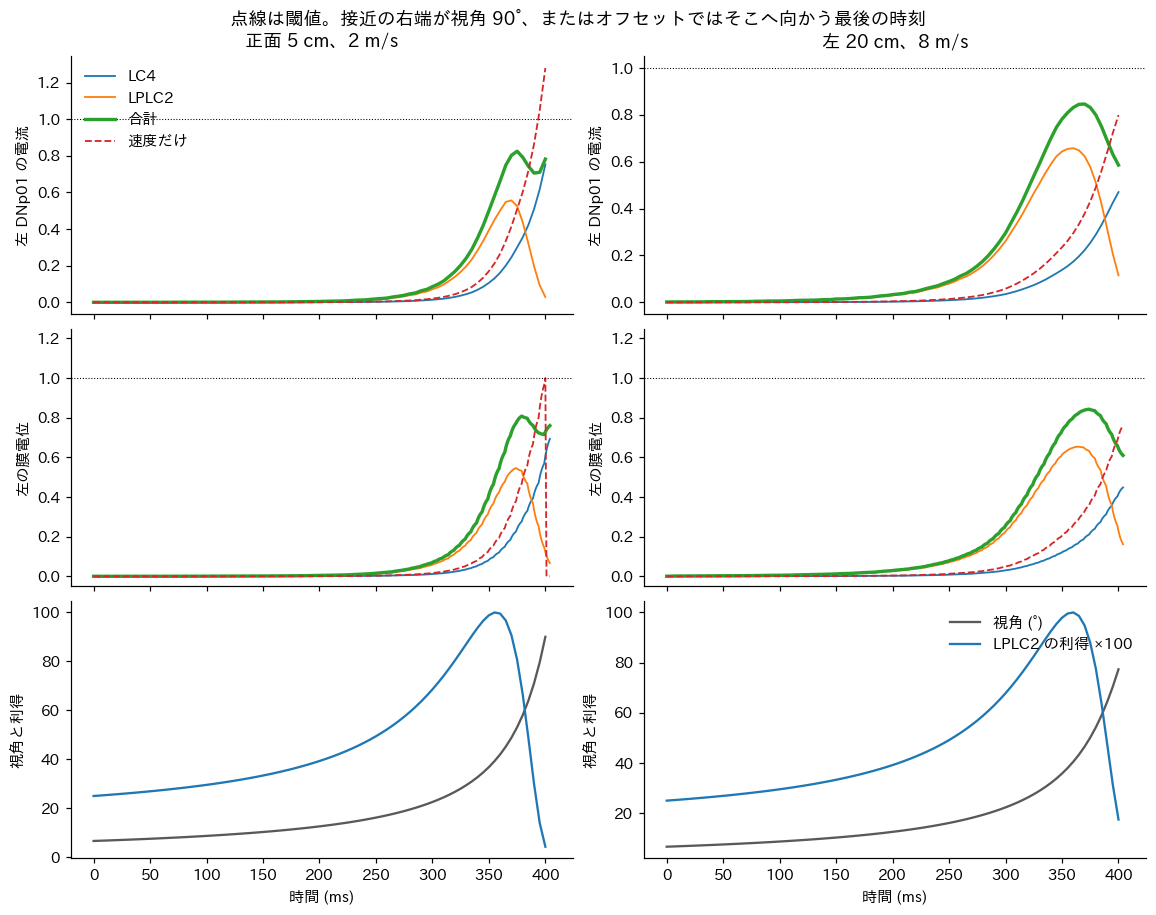

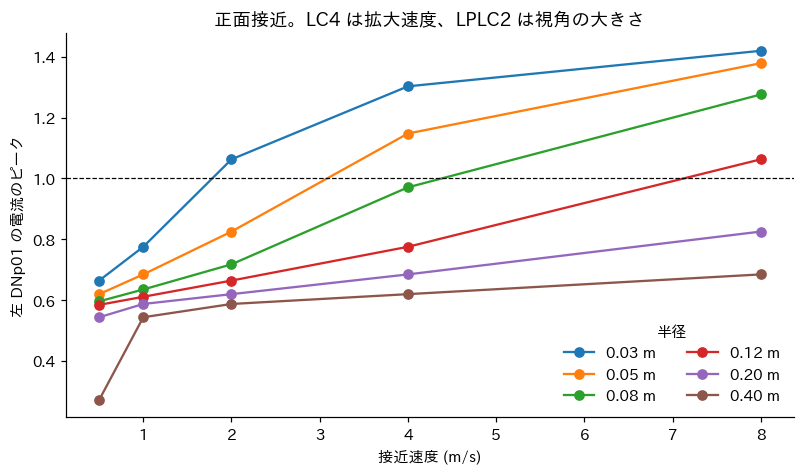

In [6]:
examples = []
for label, positions, velocity, radius in (
    ("正面 5 cm、2 m/s", *approach_path(0.05, 2.0, 0.0), 0.05),
    ("左 20 cm、8 m/s", *approach_path(0.20, 8.0, 0.15), 0.20),
):
    summary, detail = simulate(positions, velocity, radius, keep=True)
    examples.append((label, summary, detail))
    print(
        f"{label}  最大視角 {summary['視角']:.0f}°  最大拡大 {summary['拡大速度']:.1f}  "
        f"合計の山は視角 {summary['合計時の視角左']:.0f}°  拡大 {summary['合計時の拡大左']:.1f}  "
        f"大きさ {summary['合計時の大きさ左']:.2f}  "
        f"LC4 {summary['LC4電流左']:.2f}  LPLC2 {summary['LPLC2電流左']:.2f}  "
        f"合計 {summary['合計電流左']:.2f}  速度だけ {summary['速度だけ電流左']:.2f}  "
        f"スパイク 合計 {summary['合計スパイク左']}/{summary['合計スパイク右']}  "
        f"速度だけ {summary['速度だけスパイク左']}/{summary['速度だけスパイク右']}"
    )

fig, axes = plt.subplots(3, 2, figsize=(10.4, 8.0), sharex="col", constrained_layout=True)
styles = (("LC4", 1.2, "-"), ("LPLC2", 1.2, "-"), ("合計", 2.2, "-"), ("速度だけ", 1.2, "--"))
for column, (label, summary, detail) in enumerate(examples):
    time_ms = detail["geom_time"] * 1000
    membrane_ms = detail["time"] * 1000
    for name, width, linestyle in styles:
        axes[0, column].plot(time_ms, detail["current"][name][:, 0], lw=width, ls=linestyle, label=name)
        axes[1, column].plot(membrane_ms, detail["voltage"][name][:, 0], lw=width, ls=linestyle, label=name)
    axes[2, column].plot(time_ms, detail["theta_deg"], color="0.35", label="視角 (°)")
    axes[2, column].plot(time_ms, detail["gain"] * 100, label="LPLC2 の利得 ×100")
    for row in range(2):
        axes[row, column].axhline(1.0, color="k", lw=0.7, ls=":")
        axes[row, column].spines["top"].set_visible(False)
        axes[row, column].spines["right"].set_visible(False)
    axes[2, column].spines["top"].set_visible(False)
    axes[2, column].spines["right"].set_visible(False)
    axes[0, column].set_title(label)
    axes[0, column].set_ylabel("左 DNp01 の電流")
    axes[1, column].set_ylabel("左の膜電位")
    axes[1, column].set_ylim(-0.05, 1.25)
    axes[2, column].set_ylabel("視角と利得")
    axes[2, column].set_xlabel("時間 (ms)")
axes[0, 0].legend(frameon=False, loc="upper left")
axes[2, 1].legend(frameon=False, loc="upper right")
fig.suptitle("点線は閾値。接近の右端が視角 90°、またはオフセットではそこへ向かう最後の時刻", y=1.02)
plt.show()

front_plot = approach.loc[approach["経路"].eq("正面")]
fig, ax = plt.subplots(figsize=(7.2, 4.2), constrained_layout=True)
for radius, part in front_plot.groupby("半径"):
    ax.plot(part["速度"], part["合計電流左"], marker="o", label=f"{radius:.2f} m")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xlabel("接近速度 (m/s)")
ax.set_ylabel("左 DNp01 の電流のピーク")
ax.set_title("正面接近。LC4 は拡大速度、LPLC2 は視角の大きさ")
ax.legend(frameon=False, title="半径", ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## 読み方

50 Hz、80 Hz、拡大速度 50 rad/s は動かしていない。変えたのは LPLC2 の発火率だけで、視角 40° を山、幅 20° のガウス関数にした。90° では利得 0.04 まで落ちる。山の 40° は計測に合わせた。幅は、山の前後で下がるように置いた値で、フィットではない。

正面では、発火が接触の直前から、視角 50° 前後の山へ移る。5 cm を 2 m/s で近づけると、速度だけの電流は 1.28 で左右 1 回出るが、分けた合計は視角 53° で 0.83 になり、スパイクは 0 である。LPLC2 がその後下がるので、接触直前に速度だけで足していた分が消える。

分けた式で正面が発火するのは、半径 3 cm は 2 m/s から、半径 5 cm は 4 m/s から、半径 8 cm と 12 cm は 8 m/s だけである。半径 20 cm は 8 m/s でも合計 0.83、半径 40 cm は 0.69 で、どちらも出ない。LC4 だけ、LPLC2 だけでは 0 回のままである。LPLC2 が片眼いっぱいでも電流は左 0.66、右 0.74 が上限だからである。

左右に 0.15 m ずらした接近も、分けた式では 0 回である。いちばん近いのは半径 12 cm で、近い側の合計が左 0.86、右 0.93 である。半径 20 cm、8 m/s では LPLC2 が 0.66 まで上がるが、その時刻の拡大速度は 12 rad/s ほどで、合計の山は視角 47° の 0.85 に留まる。速度だけの 0.80 よりは高いが、閾値の下である。

通過も 0 回である。合計が最大なのは 0.30 m 先の半径 12 cm で、視角 44°、電流 0.77 である。LPLC2 はここでも 0.66 まで来る。LC4 の拡大速度が 7 rad/s なので、和は 1 に届かない。

細胞種を分けただけでは、片眼の looming は出ない。足りない分は、いちばん近い横からの接近で電流 0.93 まで来て、閾値までおよそ 0.1、膜が確実に超える 1.25 付近までだと 0.3 ほどである。次に動かすなら、80/50 の比か、LC4 の 50 rad/s である。
